# PHẦN THỰC NGHIỆM MỞ RỘNG

**Ứng dụng mô hình Logistic Regression & Softmax Regression trên bộ dữ liệu thực tế: Open Food Facts (Tuần 1)**

- **Bộ dữ liệu**: 1.004 sản phẩm dinh dưỡng thu thập từ Open Food Facts API (`openfoodfacts_features.csv`).
- **Ý nghĩa thống kê**: Dự đoán chất lượng dinh dưỡng dựa trên 7 thành phần hóa sinh (`energy`, `fat`, `saturated_fat`, `carbohydrates`, `sugars`, `proteins`, `salt`).
- **Bài toán 1 (Binary Classification)**: Phân loại thực phẩm lành mạnh (`is_healthy`: Grade A/B là 1, Grade C/D/E là 0) bằng `LogisticRegression` (NumPy).
- **Bài toán 2 (Multi-class Classification)**: Phân loại hạng chuẩn quốc tế **Nutri-Score** (5 lớp: A, B, C, D, E) bằng `SoftmaxRegression` (NumPy).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Đọc dữ liệu Open Food Facts từ Tuần 1
data_path = '../BaiTapTuan1/Bài 2/data/other_datasets/openfoodfacts/openfoodfacts_features.csv'
if not os.path.exists(data_path):
    data_path = 'BaiTapTuan1/Bài 2/data/other_datasets/openfoodfacts/openfoodfacts_features.csv'

df = pd.read_csv(data_path)
# Lọc bỏ các mẫu không có nhãn dinh dưỡng
df = df.dropna(subset=['nutrition_grade']).copy()
print(f'Số lượng mẫu dữ liệu sạch: {len(df)}')
print('Phân bố nhãn Nutri-Score:\n', df['nutrition_grade'].value_counts())

Số lượng mẫu dữ liệu sạch: 953
Phân bố nhãn Nutri-Score:
 nutrition_grade
C    227
E    201
D    193
A    187
B    145
Name: count, dtype: int64


## 1. Chuẩn bị đặc trưng dinh dưỡng (Nutritional Features)

In [2]:
feature_cols = [
    'energy_kcal_100g', 'fat_100g', 'saturated_fat_100g',
    'carbohydrates_100g', 'sugars_100g', 'proteins_100g', 'salt_100g'
]

# Điền giá trị khuyết bằng median của từng đặc trưng
X_raw = df[feature_cols].fillna(df[feature_cols].median()).values

# Chuẩn hóa đặc trưng Z-score (Standardization)
X = (X_raw - np.mean(X_raw, axis=0)) / (np.std(X_raw, axis=0) + 1e-7)
print('Kích thước ma trận đặc trưng X:', X.shape)

Kích thước ma trận đặc trưng X: (953, 7)


## 2. Bài toán 1: Logistic Regression phân loại thực phẩm lành mạnh (`is_healthy`)
- Nhãn 1: Nutri-Score Grade A và B (Tốt cho sức khỏe)
- Nhãn 0: Nutri-Score Grade C, D, E

In [3]:
class LogisticRegression:
    def __init__(self, lr=0.1, epochs=300):
        self.lr = lr
        self.epochs = epochs
        self.losses = []

    def _sigmoid(self, z):
        return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0

        for epoch in range(self.epochs):
            z = np.dot(X, self.w) + self.b
            y_pred = self._sigmoid(z)

            loss = -np.mean(y * np.log(y_pred + 1e-15) + (1 - y) * np.log(1 - y_pred + 1e-15))
            self.losses.append(loss)

            dw = np.dot(X.T, (y_pred - y)) / n_samples
            db = np.mean(y_pred - y)

            self.w -= self.lr * dw
            self.b -= self.lr * db

    def predict(self, X):
        z = np.dot(X, self.w) + self.b
        y_pred = self._sigmoid(z)
        return (y_pred >= 0.5).astype(int)

Báo cáo đánh giá Logistic Regression (Thực phẩm lành mạnh):
                 precision    recall  f1-score   support

Unhealthy (C-E)     0.8276    0.7742    0.8000       124
  Healthy (A-B)     0.6267    0.7015    0.6620        67

       accuracy                         0.7487       191
      macro avg     0.7271    0.7378    0.7310       191
   weighted avg     0.7571    0.7487    0.7516       191

Ý nghĩa trọng số học được từ mô hình:
- energy_kcal_100g    : +0.1680
- fat_100g            : -0.5925
- saturated_fat_100g  : -0.9399
- carbohydrates_100g  : +0.1712
- sugars_100g         : -1.1171
- proteins_100g       : +0.1091
- salt_100g           : -1.1614


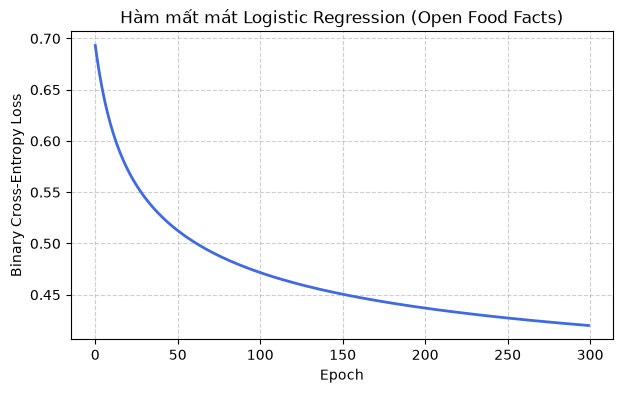

In [4]:
y_bin = df['nutrition_grade'].isin(['A', 'B']).astype(int).values
X_tr_b, X_te_b, y_tr_b, y_te_b = train_test_split(X, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

model_food_lr = LogisticRegression(lr=0.1, epochs=300)
model_food_lr.fit(X_tr_b, y_tr_b)
y_pred_b = model_food_lr.predict(X_te_b)

print('Báo cáo đánh giá Logistic Regression (Thực phẩm lành mạnh):')
print(classification_report(y_te_b, y_pred_b, target_names=['Unhealthy (C-E)', 'Healthy (A-B)'], digits=4))

# Hiển thị trọng số các thành phần dinh dưỡng
print('Ý nghĩa trọng số học được từ mô hình:')
for feat, w in zip(feature_cols, model_food_lr.w):
    print(f'- {feat:20s}: {w:+.4f}')

plt.figure(figsize=(7, 4))
plt.plot(model_food_lr.losses, color='royalblue', lw=2)
plt.title('Hàm mất mát Logistic Regression (Open Food Facts)')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 3. Bài toán 2: Softmax Regression phân loại hạng Nutri-Score (5 lớp: A, B, C, D, E)

In [5]:
class SoftmaxRegression:
    def __init__(self, lr=0.2, epochs=400):
        self.lr = lr
        self.epochs = epochs
        self.losses = []

    def _softmax(self, Z):
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.n_classes = len(np.unique(y))
        
        self.W = np.zeros((n_features, self.n_classes))
        self.b = np.zeros(self.n_classes)

        Y_onehot = np.zeros((n_samples, self.n_classes))
        Y_onehot[np.arange(n_samples), y] = 1

        for epoch in range(self.epochs):
            Z = np.dot(X, self.W) + self.b
            probs = self._softmax(Z)

            loss = -np.mean(np.sum(Y_onehot * np.log(probs + 1e-15), axis=1))
            self.losses.append(loss)

            dW = np.dot(X.T, (probs - Y_onehot)) / n_samples
            db = np.mean(probs - Y_onehot, axis=0)

            self.W -= self.lr * dW
            self.b -= self.lr * db

    def predict(self, X):
        Z = np.dot(X, self.W) + self.b
        return np.argmax(Z, axis=1)

Báo cáo đánh giá Softmax Regression trên 5 hạng Nutri-Score:
              precision    recall  f1-score   support

     Grade A     0.4308    0.7568    0.5490        37
     Grade B     0.0000    0.0000    0.0000        29
     Grade C     0.3793    0.4783    0.4231        46
     Grade D     0.5417    0.3333    0.4127        39
     Grade E     0.7381    0.7750    0.7561        40

    accuracy                         0.4921       191
   macro avg     0.4180    0.4687    0.4282       191
weighted avg     0.4400    0.4921    0.4509       191



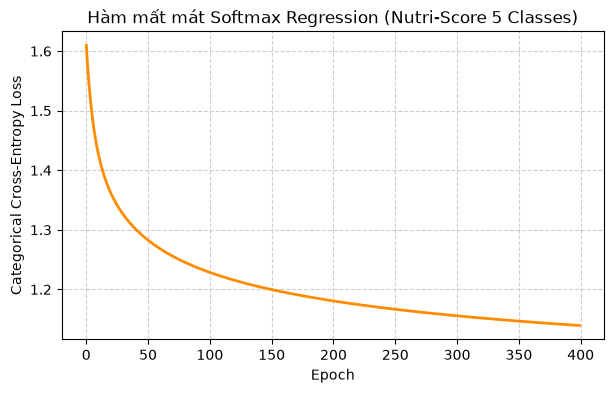

In [6]:
grade_map = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4}
y_multi = df['nutrition_grade'].map(grade_map).values
X_tr_m, X_te_m, y_tr_m, y_te_m = train_test_split(X, y_multi, test_size=0.2, random_state=42, stratify=y_multi)

model_food_softmax = SoftmaxRegression(lr=0.2, epochs=400)
model_food_softmax.fit(X_tr_m, y_tr_m)
y_pred_m = model_food_softmax.predict(X_te_m)

target_names = ['Grade A', 'Grade B', 'Grade C', 'Grade D', 'Grade E']
print('Báo cáo đánh giá Softmax Regression trên 5 hạng Nutri-Score:')
print(classification_report(y_te_m, y_pred_m, target_names=target_names, digits=4))

plt.figure(figsize=(7, 4))
plt.plot(model_food_softmax.losses, color='darkorange', lw=2)
plt.title('Hàm mất mát Softmax Regression (Nutri-Score 5 Classes)')
plt.xlabel('Epoch')
plt.ylabel('Categorical Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

## 4. Đối chứng với Scikit-Learn

In [7]:
from sklearn.linear_model import LogisticRegression as SklearnLR

# Sklearn Binary
sk_lr_bin = SklearnLR()
sk_lr_bin.fit(X_tr_b, y_tr_b)
print('=== Scikit-Learn Logistic Regression (Healthy vs Unhealthy) ===')
print(classification_report(y_te_b, sk_lr_bin.predict(X_te_b), target_names=['Unhealthy', 'Healthy'], digits=4))

# Sklearn Multi-class
sk_lr_multi = SklearnLR(max_iter=400)
sk_lr_multi.fit(X_tr_m, y_tr_m)
print('=== Scikit-Learn Softmax Regression (Nutri-Score A-E) ===')
print(classification_report(y_te_m, sk_lr_multi.predict(X_te_m), target_names=target_names, digits=4))

=== Scikit-Learn Logistic Regression (Healthy vs Unhealthy) ===
              precision    recall  f1-score   support

   Unhealthy     0.8226    0.8226    0.8226       124
     Healthy     0.6716    0.6716    0.6716        67

    accuracy                         0.7696       191
   macro avg     0.7471    0.7471    0.7471       191
weighted avg     0.7696    0.7696    0.7696       191



=== Scikit-Learn Softmax Regression (Nutri-Score A-E) ===
              precision    recall  f1-score   support

     Grade A     0.4615    0.6486    0.5393        37
     Grade B     0.0000    0.0000    0.0000        29
     Grade C     0.3333    0.5000    0.4000        46
     Grade D     0.6154    0.4103    0.4923        39
     Grade E     0.7561    0.7750    0.7654        40

    accuracy                         0.4921       191
   macro avg     0.4333    0.4668    0.4394       191
weighted avg     0.4537    0.4921    0.4616       191

